In [1]:
from svd import *


# Exercice 1 

In [2]:
import numpy as np
def svd_from_scratch_custom(A,k,tol=1e-10) : 
    # Get singular values
    AtA = A.T @ A
    eigenvalues, eigenvectors = np.linalg.eigh(AtA)
    sorted_index = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_index]
    eigenvectors = eigenvectors[:,sorted_index]
    eigenvectors = eigenvectors[:,:k]
    singular_values = np.sqrt(np.maximum(eigenvalues,0))
    singular_values = singular_values[:k]
    Sigma = np.diag(singular_values)
    V = eigenvectors
    Sigma_inverse = np.diag(1/np.maximum(singular_values,tol))
    U = A@V@Sigma_inverse

    return U ,Sigma, V

In [3]:
rng = np.random.default_rng(42)
A = rng.random((10,5))

k = 3 

U, Sigma, V = svd_from_scratch_custom(A,k)

print("A :", A.shape)
print("U :", U.shape)
print("Sigma :", Sigma.shape)
print("V :", V.shape)

A : (10, 5)
U : (10, 3)
Sigma : (3, 3)
V : (5, 3)


In [4]:
A_reconstructed = U @ Sigma @ V.T

error = np.linalg.norm(A - A_reconstructed, ord="fro")

print("Erreur de reconstruction :", error)

Erreur de reconstruction : 0.9732717119264768


In [5]:
print("U orthonormal :")
print(U.T @ U)

print("V orthonormal :")
print(V.T @ V)

U orthonormal :
[[1.00000000e+00 2.16667016e-18 4.92795877e-16]
 [2.16667016e-18 1.00000000e+00 6.71917080e-16]
 [4.92795877e-16 6.71917080e-16 1.00000000e+00]]
V orthonormal :
[[ 1.00000000e+00 -1.23437543e-16  5.43533554e-17]
 [-1.23437543e-16  1.00000000e+00  3.84975822e-16]
 [ 5.43533554e-17  3.84975822e-16  1.00000000e+00]]


In [6]:
# compare with others
A = rng.random((10,5))
k = 3

U ,Sigma, V = svd_from_scratch_custom(A,k)
U_p, Sigma_p, V_p = svd_from_scratch(A,k=3)
Sigma_p = np.diag(Sigma_p)

U_n, s_n, Vt_n = np.linalg.svd(A, full_matrices=False)
U_n = U_n[:, :k]
Sigma_n = np.diag(s_n[:k])
V_n = Vt_n[:k, :].T

A_custom = U @ Sigma @ V.T
A_power = U_p @ Sigma_p @ V_p.T
A_numpy = U_n @ Sigma_n @ V_n.T

print("Custom :", np.linalg.norm(A - A_custom, ord="fro"))
print("Power iteration :", np.linalg.norm(A - A_power, ord="fro"))
print("NumPy :", np.linalg.norm(A - A_numpy, ord="fro"))

Custom : 0.8316569536984665
Power iteration : 0.8316569537732736
NumPy : 0.8316569536984665


# Exercice 2 

(512, 512)


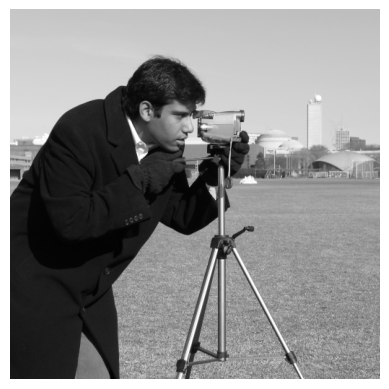

In [7]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

A = data.camera().astype(float)

print(A.shape)

plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

Compression ratio : 0.003910064697265625
Relative error : 0.36044891812313407
Compression ratio : 0.019550323486328125
Relative error : 0.17201405322952268
Compression ratio : 0.03910064697265625
Relative error : 0.1350249282451373
Compression ratio : 0.09775161743164062
Relative error : 0.09058180264540491
Compression ratio : 0.19550323486328125
Relative error : 0.06356538460461271
Compression ratio : 0.3910064697265625
Relative error : 0.03932880446586608


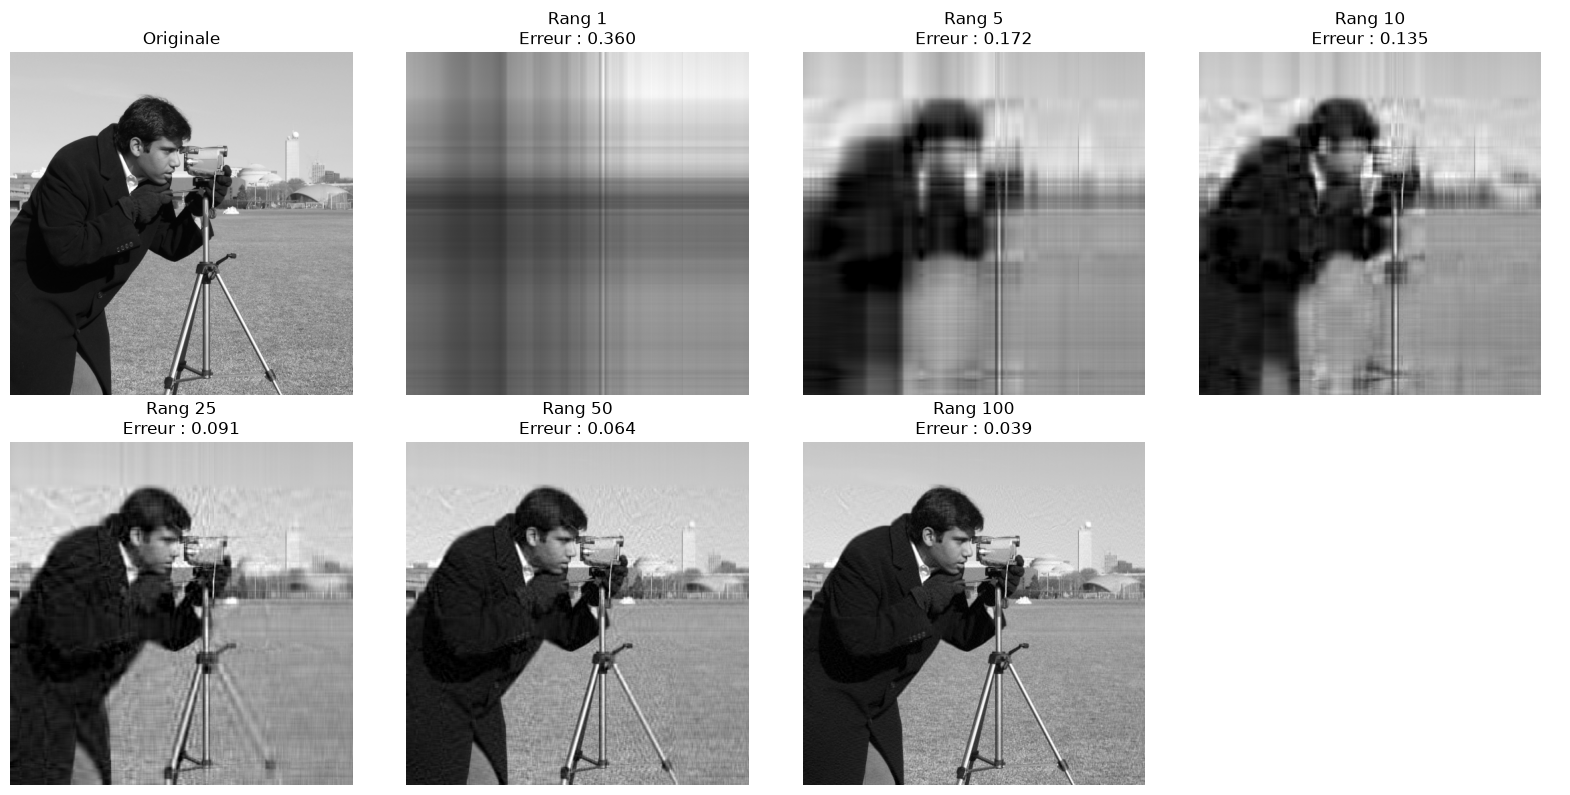

In [9]:
ranks = [1,5,10,25,50,100]
def compress_image_svd(image_matrix, k):
    U, S, Vt = np.linalg.svd(image_matrix, full_matrices=False)
    compressed = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :]
    return compressed

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Image originale
axes[0, 0].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Originale")
axes[0, 0].axis("off")

for i,r in enumerate(ranks) : 
    U,S,Vt = truncated_svd(A,r)
    reconstructed = reconstruct(U,S,Vt)
    comp_ratio = compression_ratio(A.shape[0],A.shape[1],r)
    relative_error = np.linalg.norm(A-reconstructed, ord="fro") / np.linalg.norm(A,ord="fro")
    print(f"Compression ratio : {comp_ratio}")
    print(f"Relative error : {relative_error}")
    ax = axes.flat[i + 1]
    ax.imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Rang {r}\nErreur : {relative_error:.3f}")
    ax.axis("off")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()





# Exercice 3 

In [12]:
ratings = np.array([
    [5, 4, 5, np.nan, 2, 1, 5, np.nan],
    [4, 5, 4, 1, np.nan, 2, 4, 5],
    [5, 4, np.nan, 2, 1, 2, 5, 4],
    [1, 2, 1, 5, 4, np.nan, 2, 1],
    [2, 1, 2, 4, 5, 5, np.nan, 2],
    [1, np.nan, 2, 5, 4, 5, 1, 2],
    [4, 5, 4, 2, 1, np.nan, 5, 4],
    [2, 1, np.nan, 5, 5, 4, 2, 1],
    [5, 4, 5, 1, 2, 1, np.nan, 5],
    [1, 2, 1, np.nan, 5, 4, 1, 2]
], dtype=float)

row_means = np.nanmean(ratings, axis=1)
filled = ratings.copy()

missing_rows, missing_cols = np.where(np.isnan(filled))

filled[missing_rows, missing_cols] = row_means[missing_rows]

U,S,Vt =np.linalg.svd(filled,full_matrices=False)

k = 3

reconstructed = (
    U[:, :k]
    @ np.diag(S[:k])
    @ Vt[:k, :]
)

missing_mask = np.isnan(ratings)

predictions = reconstructed[missing_mask]

missing_mask = np.isnan(ratings)

predictions = reconstructed[missing_mask]

completed = ratings.copy()

completed[missing_mask] = np.clip(
    reconstructed[missing_mask],
    1,
    5
)

print("Notes prédites :", predictions)

print("Notes prédites :", predictions)

print("Matrice originale :")
print(ratings)

print("\nMatrice après remplissage :")
print(np.round(filled, 2))

print("\nMatrice reconstruite avec SVD :")
print(np.round(reconstructed, 2))

print("\nMatrice finale :")
print(np.round(completed, 2))

Notes prédites : [3.65080298 3.65763449 2.90238343 4.21923809 3.18366821 2.14467533
 1.94808128 2.19558099 2.05180248 4.25232718 2.34192232]
Notes prédites : [3.65080298 3.65763449 2.90238343 4.21923809 3.18366821 2.14467533
 1.94808128 2.19558099 2.05180248 4.25232718 2.34192232]
Matrice originale :
[[ 5.  4.  5. nan  2.  1.  5. nan]
 [ 4.  5.  4.  1. nan  2.  4.  5.]
 [ 5.  4. nan  2.  1.  2.  5.  4.]
 [ 1.  2.  1.  5.  4. nan  2.  1.]
 [ 2.  1.  2.  4.  5.  5. nan  2.]
 [ 1. nan  2.  5.  4.  5.  1.  2.]
 [ 4.  5.  4.  2.  1. nan  5.  4.]
 [ 2.  1. nan  5.  5.  4.  2.  1.]
 [ 5.  4.  5.  1.  2.  1. nan  5.]
 [ 1.  2.  1. nan  5.  4.  1.  2.]]

Matrice après remplissage :
[[5.   4.   5.   3.67 2.   1.   5.   3.67]
 [4.   5.   4.   1.   3.57 2.   4.   5.  ]
 [5.   4.   3.29 2.   1.   2.   5.   4.  ]
 [1.   2.   1.   5.   4.   2.29 2.   1.  ]
 [2.   1.   2.   4.   5.   5.   3.   2.  ]
 [1.   2.86 2.   5.   4.   5.   1.   2.  ]
 [4.   5.   4.   2.   1.   3.57 5.   4.  ]
 [2.   1.   2.86 

# Exercice 4


In [14]:
import numpy as np

rng = np.random.default_rng(42)

# 100 documents, 50 mots
A = np.zeros((100, 50))

# Les trois topics
topics = np.array([0]*34 + [1]*33 + [2]*33)

for i in range(100):
    topic = topics[i]

    # Chaque topic possède 5 mots associés
    start = topic * 5
    end = start + 5

    # Fréquences élevées pour les mots du topic
    A[i, start:end] = rng.integers(5, 11, size=5)

noise = rng.uniform(0, 0.5, size=A.shape)

A_noisy = A + noise
print(A_noisy)

[[ 5.32596551  9.43374532  8.22694844 ...  0.40101294  0.38973877
   0.32124164]
 [10.38949818  5.0672761   9.26803402 ...  0.12669168  0.29503795
   0.0475246 ]
 [ 8.30808285 10.08564565  9.28247531 ...  0.14767951  0.22927404
   0.22115706]
 ...
 [ 0.28162807  0.14727804  0.01140012 ...  0.24166751  0.44714463
   0.13840164]
 [ 0.32921671  0.04398187  0.23696711 ...  0.17225243  0.37665481
   0.27143714]
 [ 0.12865233  0.08607894  0.08511515 ...  0.10072828  0.05146952
   0.41093523]]


In [15]:
U, S, Vt = np.linalg.svd(A,full_matrices=False)


print("10 premières valeurs singulières :")
print(S[:10])

10 premières valeurs singulières :
[98.94150005 96.60321709 94.39833966 12.63718871 12.09669674 11.7312511
 10.9013659  10.45749763 10.36571077 10.24637679]


In [16]:
X_3 = U[:, :3] @ np.diag(S[:3])

print(X_3.shape)

(100, 3)


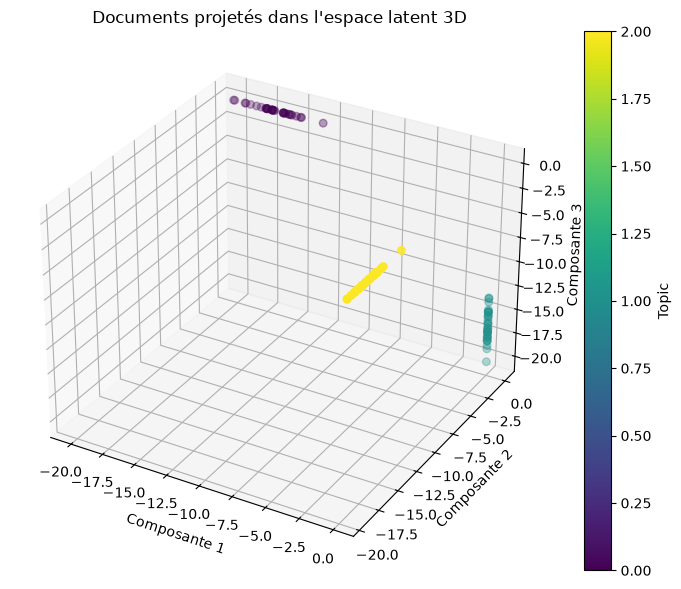

In [17]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_3[:, 0],
    X_3[:, 1],
    X_3[:, 2],
    c=topics,
    cmap="viridis",
    s=30
)

ax.set_xlabel("Composante 1")
ax.set_ylabel("Composante 2")
ax.set_zlabel("Composante 3")
ax.set_title("Documents projetés dans l'espace latent 3D")

plt.colorbar(scatter, label="Topic")
plt.show()

# Exercice 5 

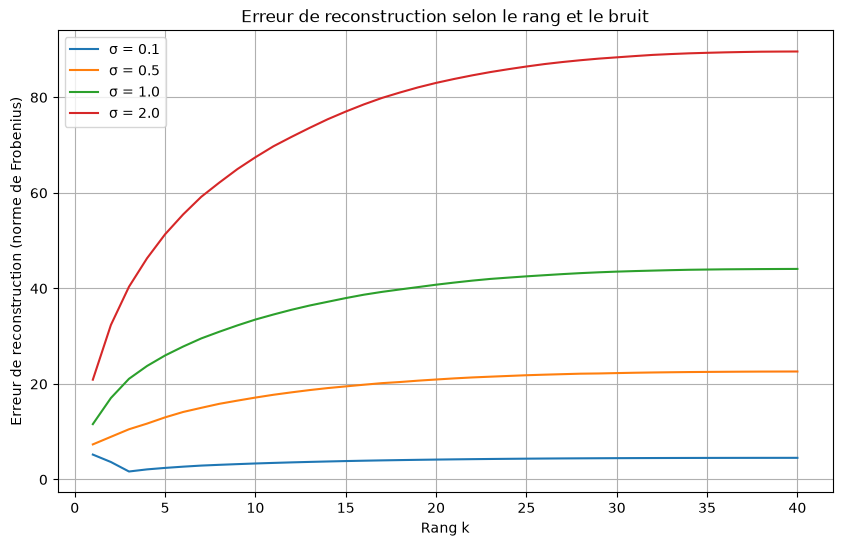

In [19]:
A = rng.random((50,3))
B  = rng.random((3,40))
low_rank = A @ B

sigmas = [0.1,0.5,1.0,2.0]
ranks = range(1, 41)
plt.figure(figsize=(10, 6))

for s in sigmas:
    noise = rng.normal(scale=s, size=low_rank.shape)
    noisy = low_rank + noise

    errors = []

    for k in ranks:
        U, S, Vt = truncated_svd(noisy, k)
        reconstructed = U @ np.diag(S) @ Vt

        error = np.linalg.norm(
            low_rank - reconstructed,
            ord="fro"
        )

        errors.append(error)

    plt.plot(ranks, errors, label=f"σ = {s}")

plt.xlabel("Rang k")
plt.ylabel("Erreur de reconstruction (norme de Frobenius)")
plt.title("Erreur de reconstruction selon le rang et le bruit")
plt.legend()
plt.grid(True)
plt.show()




σ = 0.1 | k optimal = 3
σ = 0.5 | k optimal = 1
σ = 1.0 | k optimal = 1
σ = 2.0 | k optimal = 1


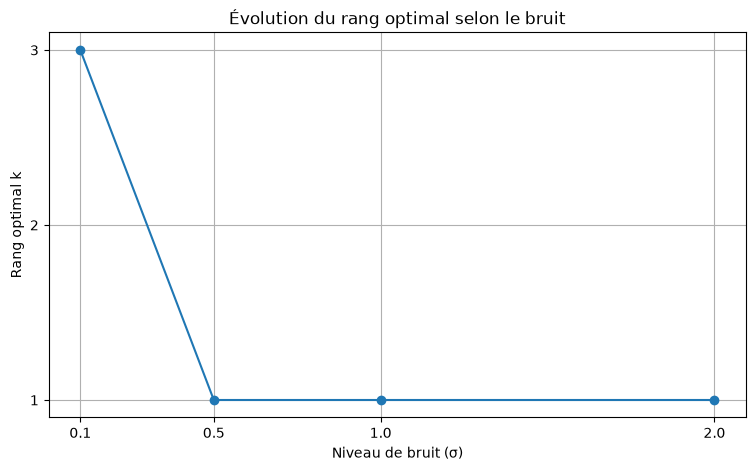

In [21]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

A = rng.random((50, 3))
B = rng.random((3, 40))
low_rank = A @ B

sigmas = [0.1, 0.5, 1.0, 2.0]
ranks = range(1, 41)

optimal_ks = []

for s in sigmas:
    noise = rng.normal(scale=s, size=low_rank.shape)
    noisy = low_rank + noise

    errors = []

    for k in ranks:
        U, S, Vt = truncated_svd(noisy, k)
        reconstructed = U @ np.diag(S) @ Vt

        error = np.linalg.norm(
            low_rank - reconstructed,
            ord="fro"
        )
        errors.append(error)

    # Trouver le rang qui minimise l'erreur
    optimal_k = np.argmin(errors) + 1
    optimal_ks.append(optimal_k)

    print(f"σ = {s} | k optimal = {optimal_k}")

# Affichage
plt.figure(figsize=(9, 5))

plt.plot(sigmas, optimal_ks, marker="o")

plt.xlabel("Niveau de bruit (σ)")
plt.ylabel("Rang optimal k")
plt.title("Évolution du rang optimal selon le bruit")

plt.xticks(sigmas)
plt.yticks(range(1, max(optimal_ks) + 1))
plt.grid(True)

plt.show()